## Análisis Numérico del Movimiento de una Partícula Sometida a una Fuerza $f_x = -m \omega^2x$ en Relatividad Especial

Caterine Bedoya Bedoya

#### 

El presente desarrollo, consiste en estudiar el comportamiento dinámico de una partícula bajo la influencia de una fuerza armónica en el marco de la Relatividad Especial. A diferencia de la mecánica clásica, en este contexto, se deben considerar las correcciones relativistas que afectan tanto la relación entre fuerza y aceleración como la evolución temporal de la partícula. El objetivo es implementar métodos numéricos para simular el movimiento de la partícula, evaluar su trayectoria y analizar cómo las predicciones relativistas difieren de las clásicas, especialmente para velocidades cercanas a la velocidad de la luz.

### Marco Teórico

La dinámica de una partícula bajo una fuerza se describe mediante la relación:

$$
F = \frac{dp}{dt},
$$

donde el momento $p$ está dado por $p = \gamma mv$, siendo $\gamma$ el factor de Lorentz.

Esto conduce a

$$
F = \frac{d}{dt}(\gamma mv),
$$

y desarrollando la derivada, se obtiene

$$
F = m\left(\gamma \frac{dv}{dt} + v\frac{d\gamma}{dt}\right).
$$

Esta expresión se puede simplificar a

$$
F = \gamma \dot{v} \left( 1 + \frac{\gamma^2 v^2}{c^2} \right).
$$

Dado que

$$
1 + \frac{\gamma^2 v^2}{c^2} = \gamma^2,
$$

la fuerza toma la forma:

$$
F = m \gamma^3 \dot{v} = -m \omega^2 x.
$$

Finalmente, la ecuación del movimiento relativista queda como

$$
\dot{v} + \omega^2x \left(1-\frac{v^2}{c^2}\right)^{3/2} = 0
$$

que es una ecuación diferencial de segundo orden que se puede resolver numéricamente usando el método Odeint de la librería scipy.

Por otro lado, según [Tsamparlis], la velocidad máxima que puede alcanzar la partícula está dada por:

$$
\mu  = \frac{\omega a c \sqrt{4c^2 + \omega^2 a^2}}{2c^2 + \omega^2 a^2},
$$

donde $\mu$ es la velocidad máxima y $a$ la amplitud máxima del movimiento. En este análisis, se ha considerado $\omega = 1$ y se ha normalizado la velocidad de la luz $c$ a 1 para simplificar los cálculos.


## Desarrollo

In [1]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec


In [34]:
# Definir la velocidad de la luz normalizada
c_vel = 1

# Definir las ecuaciones diferenciales
def derivadas_relativas(U, t, freq=1):
    pos, vel = U
    dvel_dt = -freq**2 * pos * (1 - vel**2/c_vel**2)**(3/2)
    return [vel, dvel_dt]

def derivadas_clasicas(U, t, freq=1):
    pos, vel = U
    dvel_dt = -freq**2 * pos
    return [vel, dvel_dt]

def velocidad_maxima(amplitud, freq=1):
    numerador = freq * amplitud * c_vel * np.sqrt(4 * c_vel**2 + (freq * amplitud)**2)
    denominador = 2 * c_vel**2 + (freq * amplitud)**2
    return numerador / denominador

class SistemaDinamico:
    def __init__(self, estado_inicial, tiempo, freq=1):
        self.estado_inicial = estado_inicial
        self.tiempo = tiempo
        self.freq = freq
        self.solucion_relativista = odeint(derivadas_relativas, self.estado_inicial, self.tiempo, args=(self.freq,))
        self.solucion_clasica = odeint(derivadas_clasicas, self.estado_inicial, self.tiempo, args=(self.freq,))
        self.amplitud_rel = np.max(self.solucion_relativista.T[0])
        self.velocidad_max_rel = np.max(self.solucion_relativista.T[1])

    def graficar(self):
        fig = plt.figure(figsize=(12, 6))

        gs = GridSpec(2, 2, figure=fig)
        ax1 = fig.add_subplot(gs[0, 0])
        ax2 = fig.add_subplot(gs[1, 0])
        ax3 = fig.add_subplot(gs[:, 1])

        ax1.plot(self.tiempo, self.solucion_relativista.T[0], label='Relativista')
        ax1.plot(self.tiempo, self.solucion_clasica.T[0], label='Clásico')
        ax1.set_title('Posición')
        ax1.set_ylabel('X')
        ax1.legend()

        ax2.plot(self.tiempo, self.solucion_relativista.T[1], label='Relativista')
        ax2.plot(self.tiempo, self.solucion_clasica.T[1], label='Clásico')
        ax2.set_title('Velocidad')
        ax2.set_ylabel('V')
        ax2.set_xlabel('T[s]')

        ax3.plot(self.solucion_relativista.T[0], self.solucion_relativista.T[1])
        ax3.plot(self.solucion_clasica.T[0], self.solucion_clasica.T[1])
        ax3.set_title('Espacio de Fases')
        ax3.set_xlabel('X')
        ax3.set_ylabel('V')

        plt.tight_layout()
        plt.show()
        print(f'Amplitud relativista: {np.max(self.solucion_relativista.T[0])},\nAmplitud clásica: {np.max(self.solucion_clasica.T[0])}')


In [35]:
c = 1
# Definir las ecuaciones diferenciales
def dU_dt_relativista(U, t, omega= 1):
    x, v = U
    dv_dt = -omega**2 * x * (1 - v**2/c**2)**(3/2)
    return [v,dv_dt ]

def dU_dt_clasico(U, t, omega = 1):
    x, v = U
    dv_dt = -omega**2 * x
    return [v, dv_dt]

def max_vel(a,omega = 1):
  num = omega*a*c*np.sqrt(4*c**2+(omega*a)**2)
  den = 2*c**2+(omega*a)**2
  return num/den

class sistema:
  def __init__(self,X0,time,omega = 1):
    self.X0 = X0
    self.time = time
    self.omega = omega
    self.solRel = odeint(dU_dt_relativista,self.X0,self.time,args = (self.omega,))
    self.solCla = odeint(dU_dt_clasico,self.X0,self.time,args = (self.omega,))
    self.a = np.max(self.solRel.T[0])
    self.vmax = np.max(self.solRel.T[1])

  def plot(self):
    fig = plt.figure(figsize = (12,6))

    gs = GridSpec(2, 2, figure=fig)
    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[1,0])
    ax3 = fig.add_subplot(gs[:,1])

    ax1.plot(self.time,self.solRel.T[0],label = 'Relativista')
    ax1.plot(self.time,self.solCla.T[0],label = 'Clásico')
    ax1.set_title('Posición')
    ax1.set_ylabel('X')
    ax1.legend()

    ax2.plot(self.time,self.solRel.T[1],label = 'Relativista')
    ax2.plot(self.time,self.solCla.T[1],label = 'Clásico')
    ax2.set_title('Velocidad')
    ax2.set_ylabel('V')
    ax2.set_xlabel('T[s]')


    ax3.plot(self.solRel.T[0],self.solRel.T[1])
    ax3.plot(self.solCla.T[0],self.solCla.T[1])
    ax3.set_title('Espacio de fáses')
    ax3.set_xlabel('X')
    ax3.set_ylabel('V')



    plt.tight_layout()
    plt.show()
    print(f'Amplitud relativista:{np.max(self.solRel.T[0])},\nAmplitud clásica: {np.max(self.solCla.T[0])}')



### Velocidad inicial $ v_0 = 0.01c $


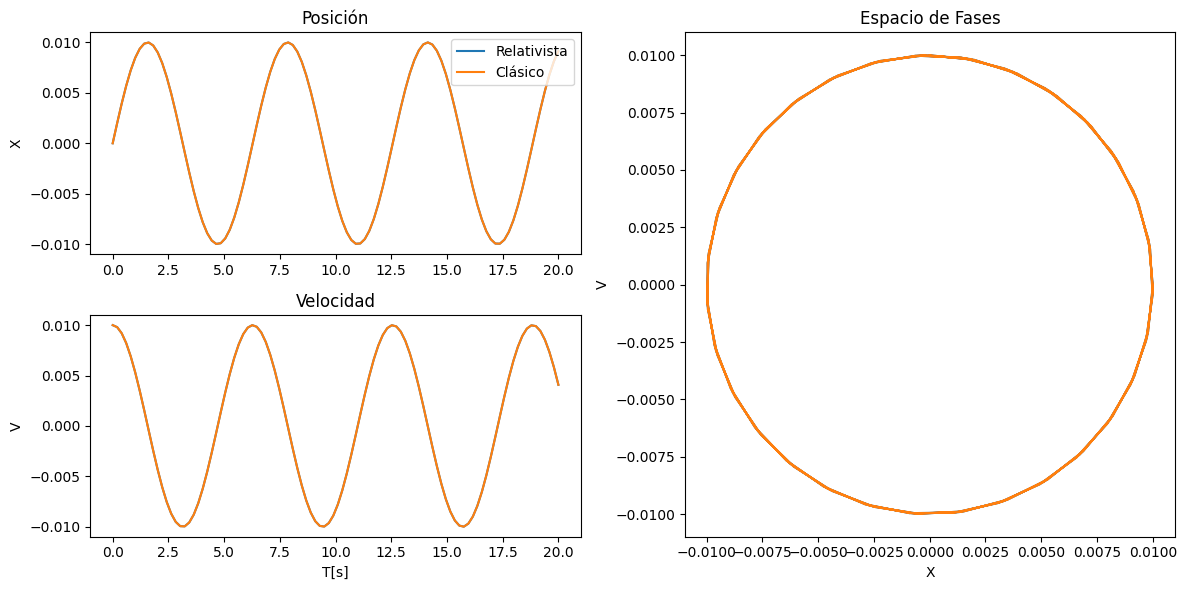

Amplitud relativista: 0.010000134861951424,
Amplitud clásica: 0.009999748794250762


In [36]:
# Definir el intervalo de tiempo y la frecuencia angular
tiempo = np.linspace(0, 20, 100)
frecuencia = 1

# Crear una instancia de la clase SistemaDinamico y graficar los resultados
sistema_dinamico = SistemaDinamico([0, 0.01 * c_vel], tiempo, frecuencia)
sistema_dinamico.graficar()


In [18]:
# Calcular la amplitud y la velocidad máxima
amplitud_relativista = sistema_dinamico.amplitud_rel
velocidad_max_rel = sistema_dinamico.velocidad_max_rel

# Calcular la velocidad máxima teórica usando la función velocidad_maxima
velocidad_maxima_teorica = velocidad_maxima(amplitud_relativista, frecuencia)

# Imprimir los resultados
(velocidad_maxima_teorica, velocidad_max_rel)


(0.009999759864748324, 0.01)

De lo anterior se ve que la velocidad máxima relativista sigue la fórmula dada en la teoría

### Velocidad inicial $ v_0 = 0.1c $

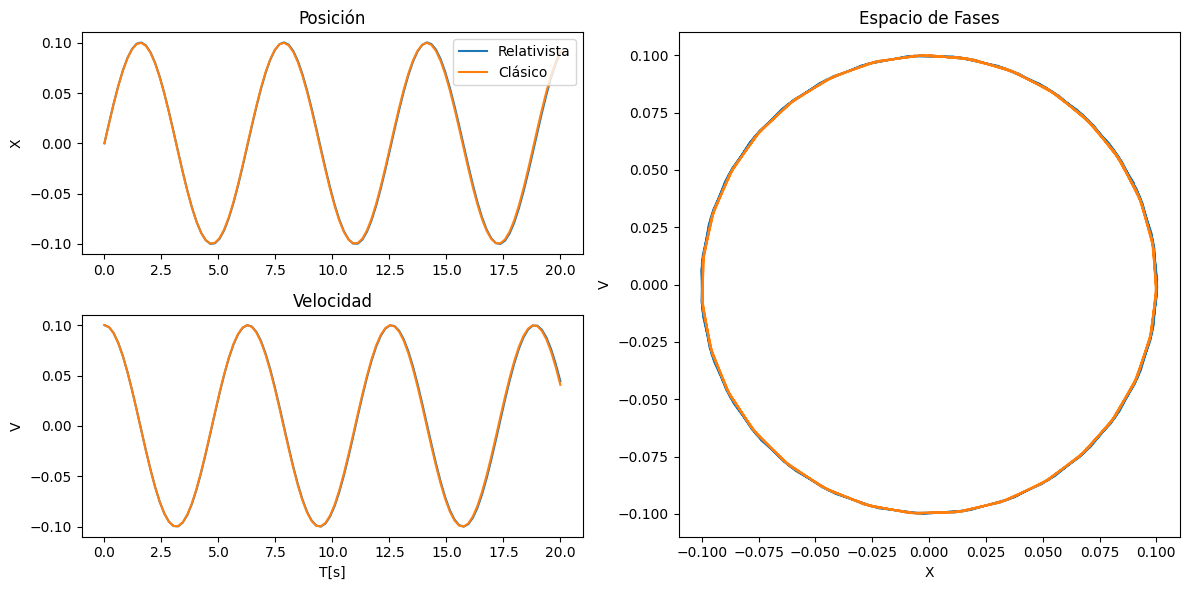

Amplitud relativista: 0.10037241109481583,
Amplitud clásica: 0.09999918208604706


In [20]:
# Crear una instancia de la clase SistemaDinamico y graficar los resultados
sistema_dinamico = SistemaDinamico([0, 0.1 * c_vel], tiempo, frecuencia)
sistema_dinamico.graficar()


In [21]:
# Calcular la amplitud y la velocidad máxima
amplitud_relativista = sistema_dinamico.amplitud_rel
velocidad_max_rel = sistema_dinamico.velocidad_max_rel

# Calcular la velocidad máxima teórica usando la función velocidad_maxima
velocidad_maxima_teorica = velocidad_maxima(amplitud_relativista, frecuencia)

# Imprimir los resultados
(velocidad_maxima_teorica, velocidad_max_rel)

(0.09999502735651987, 0.1)

En este caso, aunque la velocidad es diez veces superior a la del escenario previo, las diferencias entre los comportamientos clásico y relativista permanecen casi invisibles. Sin embargo, en contraste con el caso anterior, la posición máxima alcanzada por la partícula muestra una discrepancia más significativa cuando la velocidad inicial es $v_0 = 0.01c$.

### Velocidad inicial $ v_0 = 0.4c $

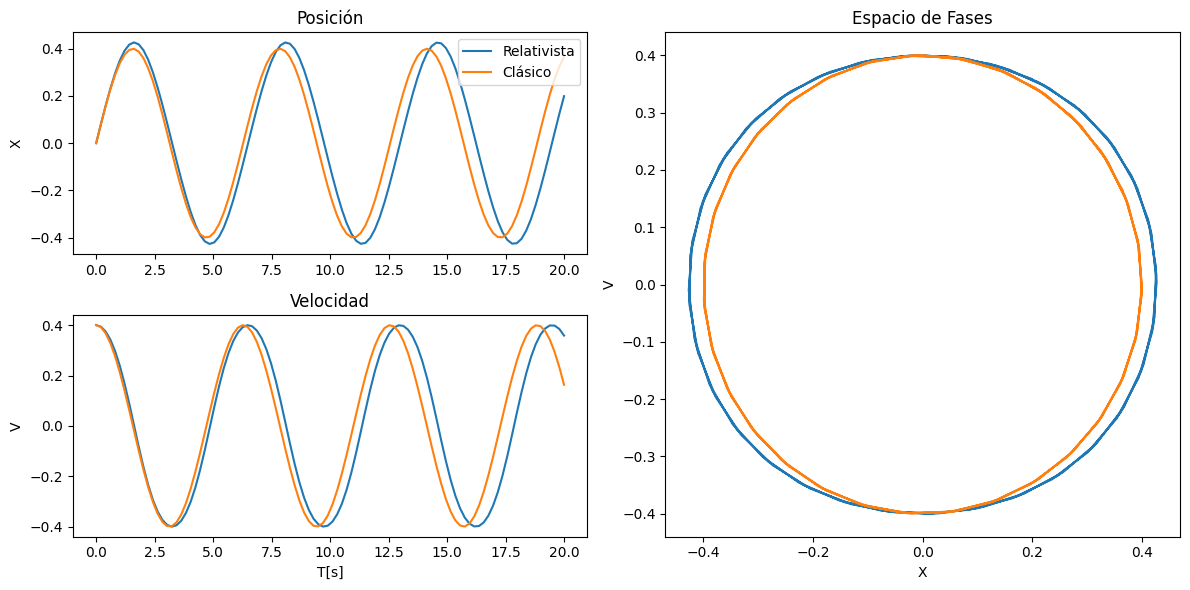

Amplitud relativista: 0.4268121903346549,
Amplitud clásica: 0.3999965101228555


In [22]:
# Crear una instancia de la clase SistemaDinamico y graficar los resultados
sistema_dinamico = SistemaDinamico([0, 0.4 * c_vel], tiempo, frecuencia)
sistema_dinamico.graficar()


In [23]:
# Calcular la amplitud y la velocidad máxima
amplitud_relativista = sistema_dinamico.amplitud_rel
velocidad_max_rel = sistema_dinamico.velocidad_max_rel

# Calcular la velocidad máxima teórica usando la función velocidad_maxima
velocidad_maxima_teorica = velocidad_maxima(amplitud_relativista, frecuencia)

# Imprimir los resultados
(velocidad_maxima_teorica, velocidad_max_rel)

(0.39999012951914037, 0.4)

Dada $v_0 = 0.4c$ se observa cómo se empiezan a generar desviaciones en la posición, velocidad y espacio de fases.

### Velocidad inicial $ v_0 = 0.6c $

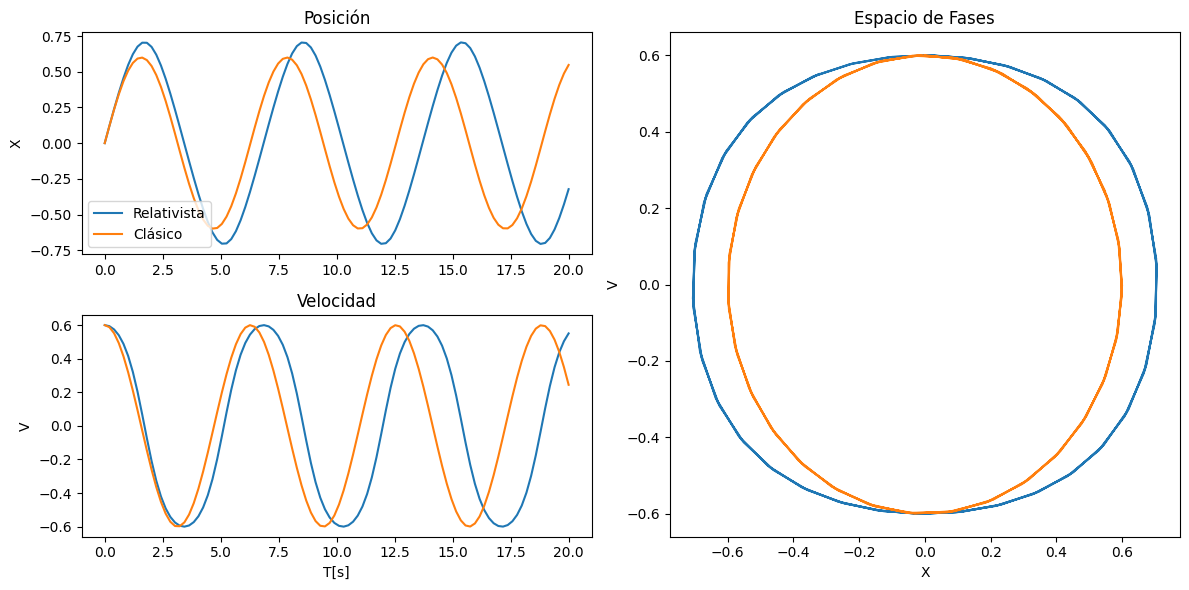

Amplitud relativista: 0.7058059221428579,
Amplitud clásica: 0.5999946450730379


In [25]:
# Crear una instancia de la clase SistemaDinamico y graficar los resultados
sistema_dinamico = SistemaDinamico([0, 0.6 * c_vel], tiempo, frecuencia)
sistema_dinamico.graficar()


In [26]:
# Calcular la amplitud y la velocidad máxima
amplitud_relativista = sistema_dinamico.amplitud_rel
velocidad_max_rel = sistema_dinamico.velocidad_max_rel

# Calcular la velocidad máxima teórica usando la función velocidad_maxima
velocidad_maxima_teorica = velocidad_maxima(amplitud_relativista, frecuencia)

# Imprimir los resultados
(velocidad_maxima_teorica, velocidad_max_rel)

(0.5992144065755054, 0.6)

### Velocidad inicial $ v_0 = 0.8c $

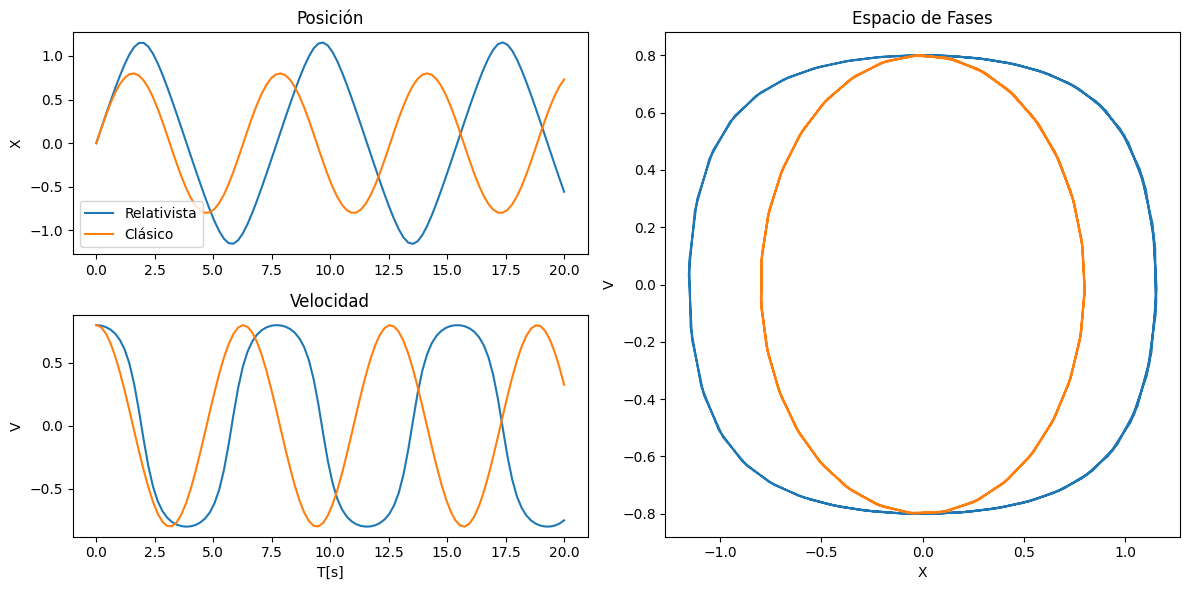

Amplitud relativista: 1.1546141863988844,
Amplitud clásica: 0.7999929452466392


In [27]:
# Crear una instancia de la clase SistemaDinamico y graficar los resultados
sistema_dinamico = SistemaDinamico([0, 0.8 * c_vel], tiempo, frecuencia)
sistema_dinamico.graficar()

In [28]:
# Calcular la amplitud y la velocidad máxima
amplitud_relativista = sistema_dinamico.amplitud_rel
velocidad_max_rel = sistema_dinamico.velocidad_max_rel

# Calcular la velocidad máxima teórica usando la función velocidad_maxima
velocidad_maxima_teorica = velocidad_maxima(amplitud_relativista, frecuencia)

# Imprimir los resultados
(velocidad_maxima_teorica, velocidad_max_rel)

(0.7999730762545039, 0.8)

### Velocidad inicial $ v_0 = 0.9c $

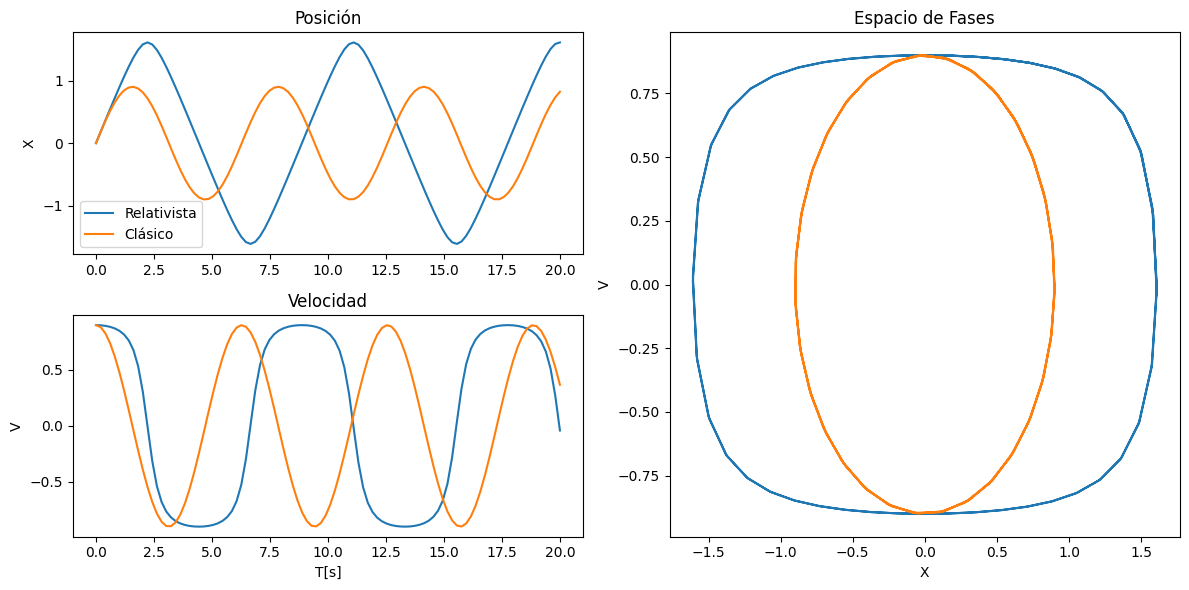

Amplitud relativista: 1.6088167018930553,
Amplitud clásica: 0.8999921438656379


In [29]:
# Crear una instancia de la clase SistemaDinamico y graficar los resultados
sistema_dinamico = SistemaDinamico([0, 0.9 * c_vel], tiempo, frecuencia)
sistema_dinamico.graficar()


In [30]:
# Calcular la amplitud y la velocidad máxima
amplitud_relativista = sistema_dinamico.amplitud_rel
velocidad_max_rel = sistema_dinamico.velocidad_max_rel

# Calcular la velocidad máxima teórica usando la función velocidad_maxima
velocidad_maxima_teorica = velocidad_maxima(amplitud_relativista, frecuencia)

# Imprimir los resultados
(velocidad_maxima_teorica, velocidad_max_rel)

(0.8999989188744028, 0.9)

Para este caso, la discrepancia entre los dos tipos de movimiento se hace mucho más clara. Mientras que el movimiento clásico sigue un patrón similar al de bajas velocidades, el movimiento relativista se retrasa y alcanza una mayor amplitud. Esto resalta la necesidad de utilizar la teoría relativista, ya que desde el comienzo del movimiento, se observan diferencias significativas entre ambos comportamientos.

#### Simulación del Movimiento Clásico y Relativista de la Partícula


In [33]:
rc('animation', html='html5')
from matplotlib import animation
from matplotlib import rc

# Configuración para la animación en formato HTML5
rc('animation', html='html5')

fig, ax = plt.subplots()

# Crear una instancia del sistema dinámico
sistema_dinamico = SistemaDinamico([0, 0.9 * c_vel], tiempo, frecuencia)

# Inicializar los puntos de datos para la animación
punto_relativista = ax.scatter([], [], s=100, c='#1f77b4', label='Relativista')
punto_clasico = ax.scatter([], [], s=100, color='orange', label='Clásico')

plt.legend()

# Ajustar los límites del eje
lim_x = np.max(sistema_dinamico.solucion_relativista.T[0])
ax.set_xlim([-lim_x, lim_x])
plt.axis("off")

# Función de actualización para la animación
def actualizar(i):
    punto_relativista.set_offsets([sistema_dinamico.solucion_relativista.T[0][i], 0])
    punto_clasico.set_offsets([sistema_dinamico.solucion_clasica.T[0][i], 0])

# Crear la animación
animacion = animation.FuncAnimation(fig, actualizar, frames=len(tiempo), interval=20)

plt.close()
animacion


#### Conclusiones
Es evidente que, cuando las velocidades son muy bajas en comparación con la velocidad de la luz, las diferencias entre los comportamientos relativista y clásico son mínimas. A medida que se incrementa la velocidad inicial, estas diferencias comienzan a hacerse más notables. Sin embargo, este cambio no sigue una relación lineal con el aumento de la velocidad; por ejemplo, al pasar de $v = 0.01c$ a $v = 0.1c$, que representa un aumento de diez veces, las diferencias no son significativas. En cambio, al aumentar de $v = 0.8c$ a $v = 0.9c$, se observa una diferencia bastante marcada. En el marco relativista, el movimiento parece 'retrasarse', ya que se requiere más tiempo para completar un ciclo y la posición máxima alcanzada es mayor que en el caso clásico.

Por otro lado, en el espacio de fases, para el caso clásico, la velocidad máxima y la posición máxima tienen el mismo valor numérico, lo que se representa como una circunferencia en dicho espacio. En contraste, para el caso relativista, a medida que la velocidad inicial se aproxima a la velocidad de la luz, el gráfico en el espacio de fases se expande en comparación con el caso clásico. Finalmente, al determinar la velocidad máxima usando la fórmula de Tsamparlis con la amplitud máxima obtenida, se confirma el valor de la velocidad inicial, lo que sugiere que el desarrollo del proyecto es correcto.


# Referencias

Tsamparlis, M. (2010). *Special relativity–An introduction with 200 problems and solutions* (Chap. 15, The covariant Lorentz transformation). Springer. doi:10.1007/978-3-642-10545-0
